<a href="https://colab.research.google.com/github/skurakake/hello-world/blob/master/CNN_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 21s 0us/step
Image size: (32, 32, 3)
(32, 32, 3)


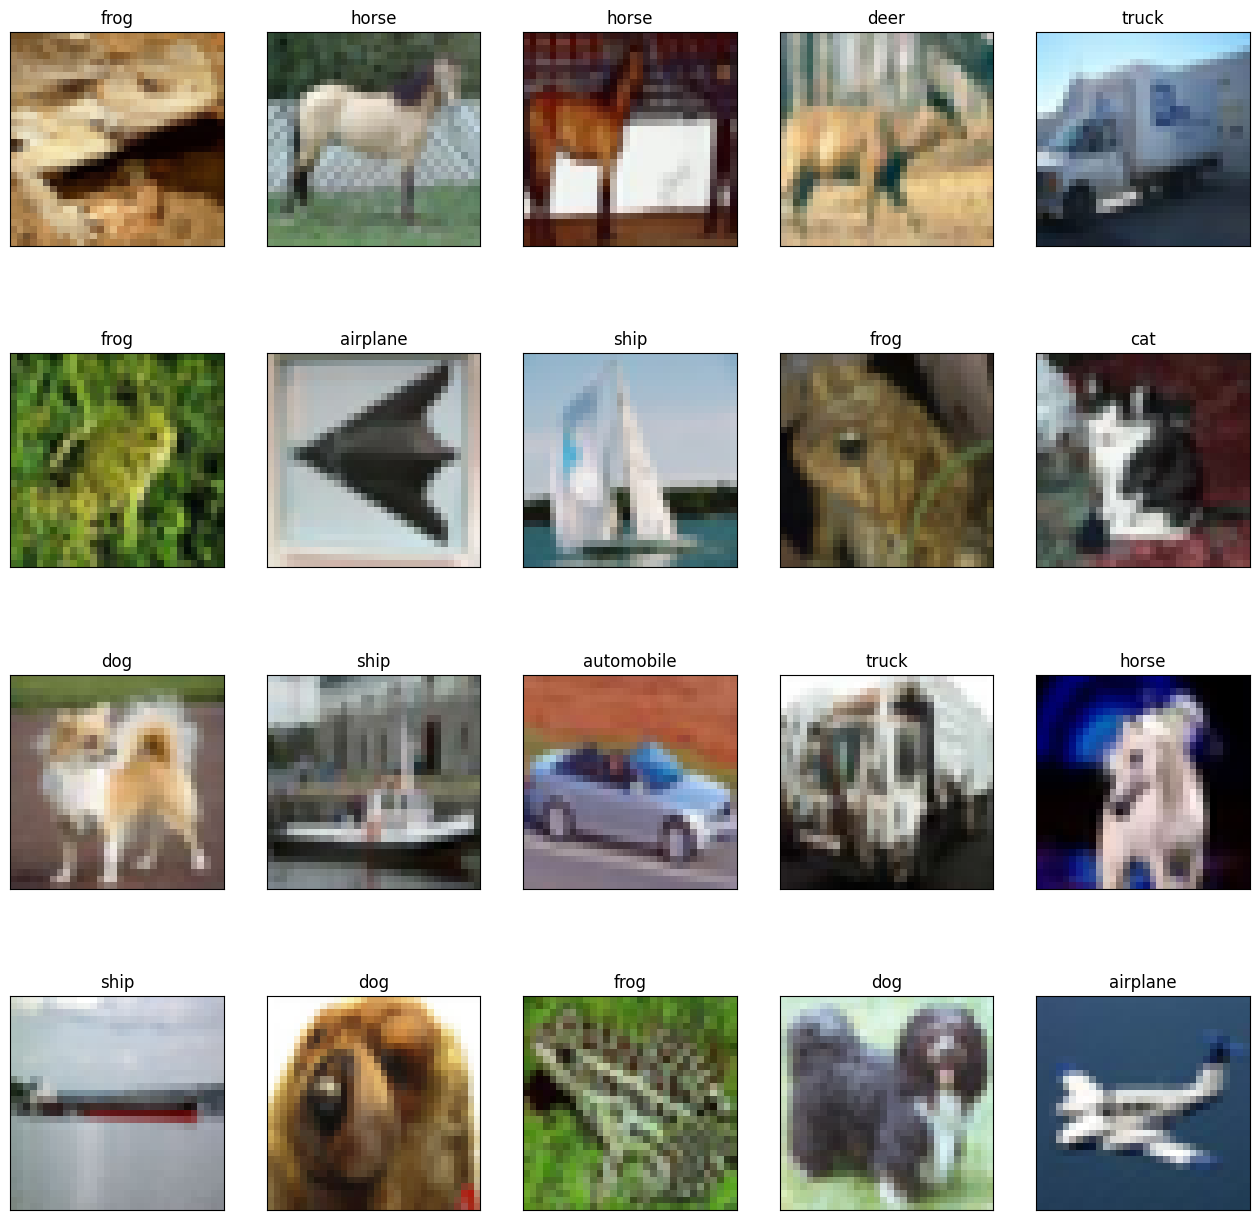

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10

(x_train, t_train), (x_test, t_test) = cifar10.load_data()
print("Image size:", x_train[0].shape)
print(x_test[0].shape)

cifar10_labels = np.array(["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"])

num_image = 20
rand_idx = np.random.randint(0, len(x_train), num_image)
plt.figure(figsize=(16, 16))

for i in range(num_image):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_train[rand_idx[i]])
    plt.title(cifar10_labels[t_train[rand_idx[i]][0]])
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

plt.show()


In [2]:
# 設定
batch_size = 32 # ミニバッチサイズ
epochs = 20 # エポック数
num_class = 10 # クラス数

# 正解データを one-hot 表現へ変換
t_train_n = tf.keras.utils.to_categorical(t_train, num_class)
t_test_n = tf.keras.utils.to_categorical(t_test, num_class)
print(t_train_n[:10])


[[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]]


モデルの構築

In [3]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, Flatten
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.optimizers import SGD

model = Sequential()

model.add(Input(shape=x_train.shape[1:]))# .shape の2番目から最後までの要素 (32,32,3)
model.add(Conv2D(64,(3,3), strides=1,  padding = 'same')) #padding = 'same' 入力と同じサイズになるまで０パディング
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Conv2D(64,(3,3), strides=1,  padding = 'same')) #padding = 'same' 入力と同じサイズになるまで０パディング
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2), strides=2))

model.add(Conv2D(128,(3,3), strides=1,  padding = 'same')) #padding = 'same' 入力と同じサイズになるまで０パディング
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(Conv2D(128,(3,3), strides=1,  padding = 'same')) #padding = 'same' 入力と同じサイズになるまで０パディング
model.add(BatchNormalization())
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2), strides=2))

model.add(Flatten())
model.add(Dropout(0.2))
model.add(Dense(4096))
model.add(Dropout(0.2))
model.add(Dense(4096))
model.add(Dense(num_class))
model.add(Activation('softmax'))

model.compile(loss='categorical_crossentropy', optimizer=SGD(), metrics=['accuracy'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4096)           │    33,558,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │        40,970 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 10)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,642,506 (193.19 MB)

 Trainable params: 50,641,738 (193.18 MB)

 Non-trainable params: 768 (3.00 KB)

モデルを訓練する

In [4]:
x_train =x_train /255
x_test = x_test /255
history = model.fit(x_train, t_train_n, batch_size=batch_size,
                    epochs=epochs, validation_data=(x_test, t_test_n))

Epoch 1/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 36s 18ms/step - accuracy: 0.3570 - loss: 3.2633 - val_accuracy: 0.5257 - val_loss: 1.3269
Epoch 2/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 14ms/step - accuracy: 0.5791 - loss: 1.1807 - val_accuracy: 0.6335 - val_loss: 1.0247
Epoch 3/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.6679 - loss: 0.9498 - val_accuracy: 0.5567 - val_loss: 1.3663
Epoch 4/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.7104 - loss: 0.8276 - val_accuracy: 0.6659 - val_loss: 0.9542
Epoch 5/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 41s 14ms/step - accuracy: 0.7396 - loss: 0.7473 - val_accuracy: 0.6047 - val_loss: 1.3210
Epoch 6/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.7692 - loss: 0.6628 - val_accuracy: 0.6933 - val_loss: 0.8911
Epoch 7/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - accuracy: 0.7868 - loss: 0.6110 - val_accuracy: 0.7273 - val_loss: 0.7968
Epoch 8/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.8027 -

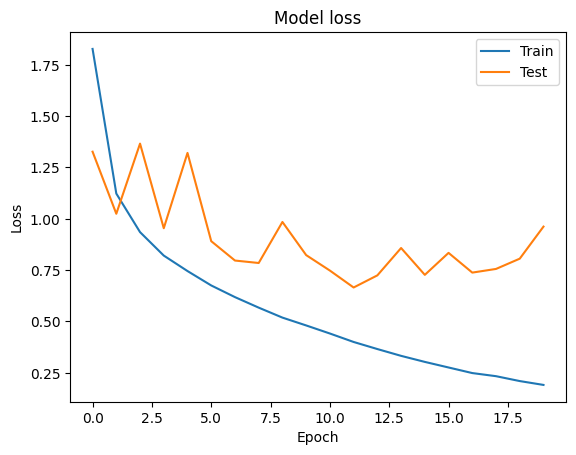

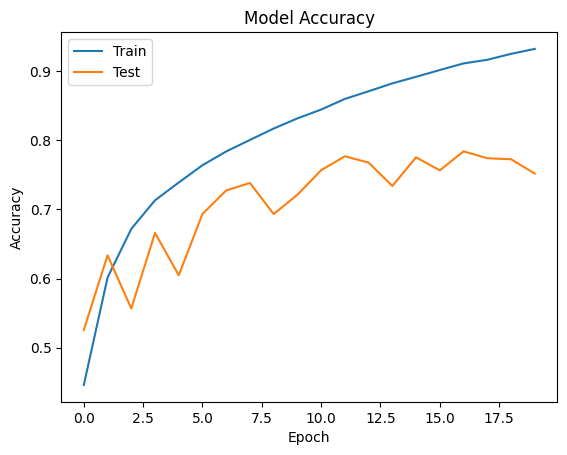

In [5]:
# 学習の経過をグラフで表示
import matplotlib.pyplot as plt
train_loss = history.history['loss']
train_accuracy = history.history['accuracy']
validation_loss = history.history['val_loss']
validation_accuracy = history.history['val_accuracy']

plt.plot(np.arange(len(train_loss)), train_loss, label='training_loss')
plt.plot(np.arange(len(validation_loss)), validation_loss, label='validation_loss')
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper right')
plt.show()

plt.plot(np.arange(len(train_accuracy)), train_accuracy, label='training_accuracy')
plt.plot(np.arange(len(validation_accuracy)), validation_accuracy, label='validation_accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

テストデータ全体に対して精度とlossを求める

In [6]:
loss, accuracy = model.evaluate(x_test, t_test_n)
print('Test loss:', loss)
print('Test accuracy:', accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7518 - loss: 0.9570
Test loss: 0.9620546698570251
Test accuracy: 0.7516999840736389


学習済みのモデルを使って、テストデータの中からランダムに選択したデータに対して分類を行う。

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


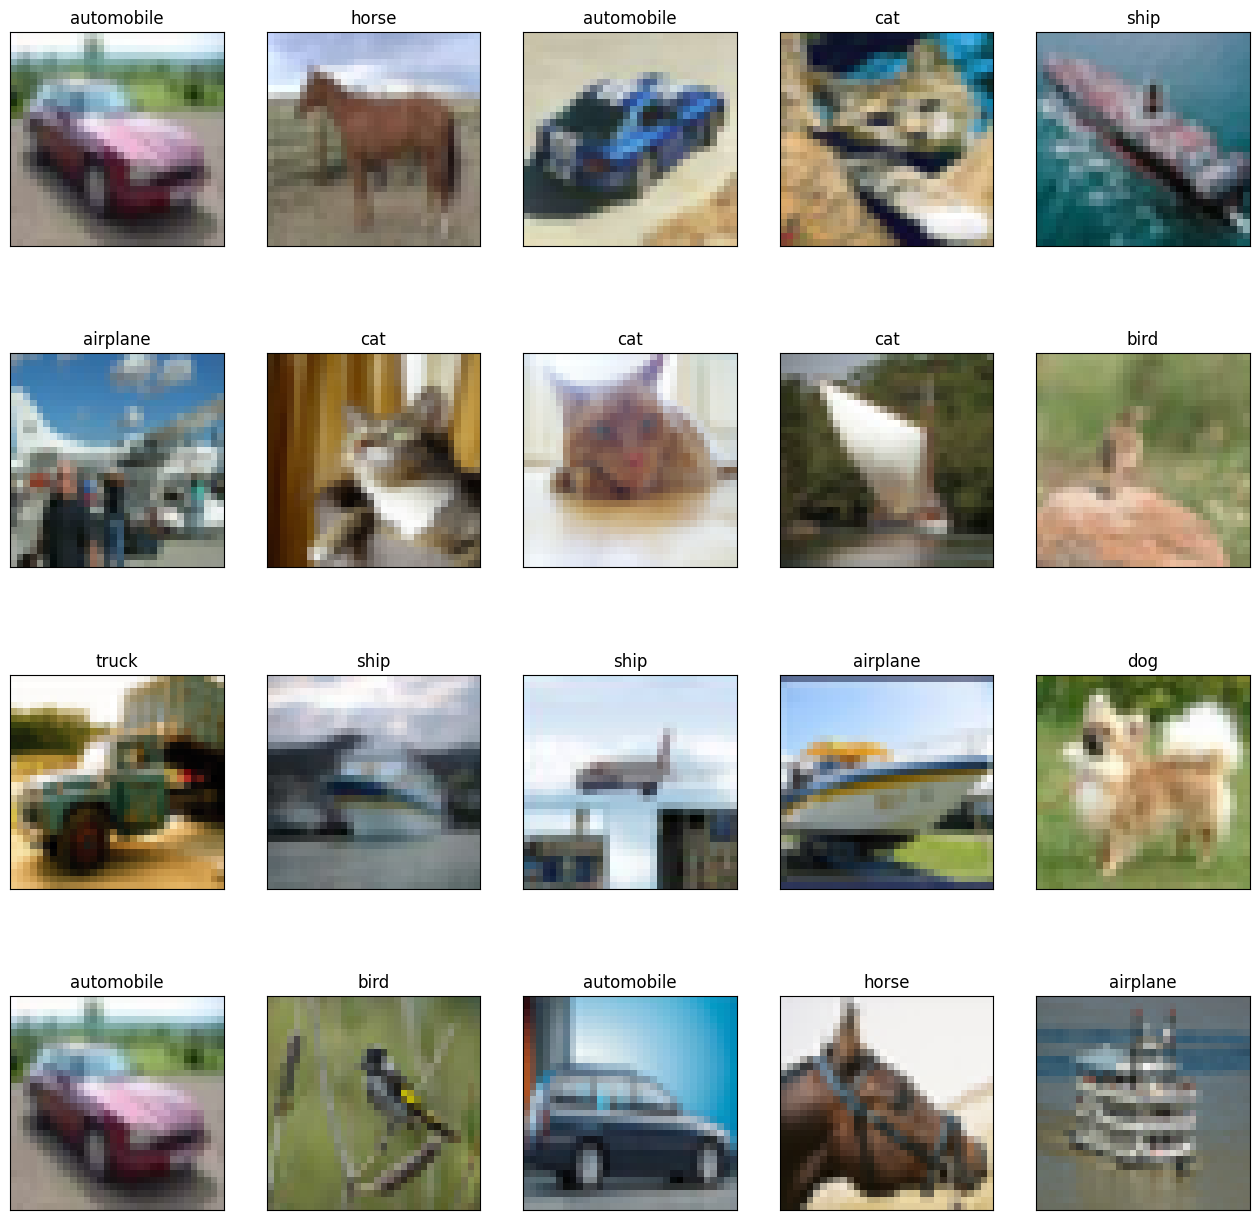

In [ ]:
num2_image = 20
rand_idx2 = np.random.randint(0, len(x_test), num2_image)

y_rand = model.predict(x_test[rand_idx2]) # テストデータからランダムに画像を選択して、画像分類を実行
predicted_class = np.argmax(y_rand, axis=1) # 分類結果の中で最大値を取るインデックスを取得

plt.figure(figsize=(16,16)) # 画像の表示サイズ

for i in range(num2_image):
    plt.subplot(4, 5, i + 1)
    plt.imshow(x_test[rand_idx2[i]])
    label = cifar10_labels[predicted_class[i]]
    plt.title(label)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

plt.show()


学習済みのモデルをgoogle drive に保存

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/MyDrive/Colab_Notebooks/colabMount


In [7]:
import os
from keras.models import load_model

path = '/content/drive/MyDrive/Colab Notebooks/'

if not os.path.exists(path):
    os.makedirs(path)

#
model.save(path + "model_cnn_cifar10.keras")